# MAE 6246 — Week 13: Ball-and-beam LQG stabilization and output tracking
**Linear Systems and Control · November 20, 2026**

We first stabilize the centered, horizontal equilibrium of the ball-and-beam system from class:
1. Infinite-horizon LQR: design state feedback and test it with the full state.
2. Infinite-horizon Kalman filter: compute the steady prior covariance and fixed correction gain.
3. LQG: combine the controller and estimator, simulate, and animate stabilization.
4. Track a time-varying output by stabilizing the new state $\tilde x=x-x_r(t)$.
5. Specialize the same controller to a fixed output reference.

The tracking sections follow stabilization and use the same LQR and fixed Kalman gains. The measured output is beam angle; the tracked output is ball position.

Run all cells in order. In Colab, the setup cell downloads `mjsim.py` automatically if it is missing. Locally, keep `mjsim.py` beside this notebook. The module supplies the physical parameters, plant matrices, equilibrium, sample period, torque limit, simulation, and animation. We choose the LQR penalties and estimator noise assumptions here. The course model treats the ball as a sliding mass, without rolling inertia.

In [1]:
import importlib.util
import subprocess
import sys

packages = {"numpy": "numpy", "scipy": "scipy", "matplotlib": "matplotlib",
            "mujoco": "mujoco", "imageio_ffmpeg": "imageio-ffmpeg"}
missing = [package for module, package in packages.items()
           if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])

%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import solve_discrete_are
from IPython.display import display, Video, Markdown
# Colab opens the notebook alone; fetch its companion module when needed.
from pathlib import Path
from urllib.request import urlretrieve

module = Path("mjsim.py")
if not module.is_file():
    module_url = ("https://raw.githubusercontent.com/fdcl-gwu/MAE6246/"
                  "main/notebooks/week13/mjsim.py")
    urlretrieve(module_url, module)
    print("Downloaded mjsim.py from the course repository.")

import mjsim

np.set_printoptions(precision=5, suppress=True)

## Load the provided system
The state order is $x=[d,\dot d,\theta,\dot\theta]^T$. The actuator applies beam-pivot torque and the sensor measures beam angle. Positive $\theta$ raises the right-hand end.

Load the model rather than rebuilding its matrices. Use $H$ for the sensor matrix and $z_k$ for the noisy measurement, matching the lecture notes. Load `H = dyn.C` and `z_eq = dyn.y_eq` from the provided wrapper.

The sampled deviation model is
$$\delta x_{k+1}=A_d\delta x_k+B_d\delta u_k+w_k,\qquad
\delta z_k=H\delta x_k+D\delta u_k+v_k.$$
Here $\delta z_k=z_k-z_{\rm eq}$. Physical states and inputs returned by the wrapper include the equilibrium offsets.

In [2]:
dyn = mjsim.load_dynamics("beam")
A, B, H, D = dyn.A, dyn.B, dyn.C, dyn.D
Ad, Bd = dyn.discrete()
x_eq, u_eq, z_eq = dyn.x_eq, dyn.u_eq, dyn.y_eq
n, m, p, dt = dyn.n, dyn.m, dyn.p, dyn.dt

dyn.info()
print("Sampled A_d =\n", Ad)
print("Sampled B_d =\n", Bd)

controllability = np.hstack([np.linalg.matrix_power(Ad, j) @ Bd for j in range(n)])
observability = np.vstack([H @ np.linalg.matrix_power(Ad, j) for j in range(n)])
print("Controllability rank:", np.linalg.matrix_rank(controllability), "/", n)
print("Observability rank:", np.linalg.matrix_rank(observability), "/", n)
assert np.linalg.matrix_rank(controllability) == n
assert np.linalg.matrix_rank(observability) == n

Dynamics 'beam':  n = 4 states, m = 1 inputs, p = 1 outputs, dt = 0.01 s
  x = ['d [m]', 'd_dot [m/s]', 'theta [rad]', 'theta_dot [rad/s]']
  u = ['torque [N m]']
  y = ['theta [rad]']
  equilibrium 'level': x_eq = [0. 0. 0. 0.]  u_eq = [0.]  y_eq = [0.]
  |u| <= [10.]
A =
[[ 0.     1.     0.     0.   ]
 [ 0.     0.    -9.81   0.   ]
 [ 0.     0.     0.     1.   ]
 [-4.905  0.     0.     0.   ]]
B =
[[0. ]
 [0. ]
 [0. ]
 [0.5]]
C =
[[0. 0. 1. 0.]]
D =
[[0.]]
Sampled A_d =
 [[ 1.      0.01   -0.0005 -0.    ]
 [ 0.      1.     -0.0981 -0.0005]
 [-0.0002 -0.      1.      0.01  ]
 [-0.0491 -0.0002  0.      1.    ]]
Sampled B_d =
 [[-0.   ]
 [-0.   ]
 [ 0.   ]
 [ 0.005]]
Controllability rank: 4 / 4
Observability rank: 4 / 4


## 1. Infinite-horizon LQR
Use the sampled model because the controller is called once per sample. Minimize the deterministic cost
$$J=\sum_{k=0}^\infty\left(\delta x_k^TQ_c\delta x_k+\delta u_k^TR_c\delta u_k\right).$$
The stabilizing Riccati solution $X$ satisfies
$$X=A_d^TXA_d+Q_c-A_d^TXB_d(R_c+B_d^TXB_d)^{-1}B_d^TXA_d.$$
Then
$$F=(R_c+B_d^TXB_d)^{-1}B_d^TXA_d,\qquad
u_k=u_{\rm eq}-F(x_k-x_{\rm eq}).$$
$X$ is a cost matrix, not an estimation covariance. Weights correspond to the state order printed above. The infinite-horizon design has a constant gain; the finite-duration simulation only tests its response.

In [3]:
Qc = np.diag([100.0, 10.0, 100.0, 10.0])
Rc = 0.1 * np.eye(m)

X = solve_discrete_are(Ad, Bd, Qc, Rc)
F = np.linalg.solve(Rc + Bd.T @ X @ Bd, Bd.T @ X @ Ad)
controller_poles = np.linalg.eigvals(Ad - Bd @ F)
print("LQR gain F =", F)
print("Closed-loop poles =", controller_poles)
assert np.max(np.abs(controller_poles)) < 1


def make_controller(dyn, F):
    """Return controller(t, xhat), in the classroom callback format."""
    def controller(t, xhat):
        return dyn.u_eq - F @ (xhat - dyn.x_eq)
    return controller

# The wrapper clips the requested torque to dyn.u_limit.
controller = make_controller(dyn, F)

LQR gain F = [[-41.0262 -27.9758 108.5876  22.7568]]
Closed-loop poles = [0.9799+0.0259j 0.9799-0.0259j 0.9674+0.j     0.9562+0.j    ]


### Full-state baseline
Start with the ball displaced from the pivot and the beam slightly tilted. These are test initial conditions, not physical model parameters. With `observer=None`, the controller receives the true state. Compare the sampled linear prediction with the nonlinear MuJoCo plant before introducing estimation.

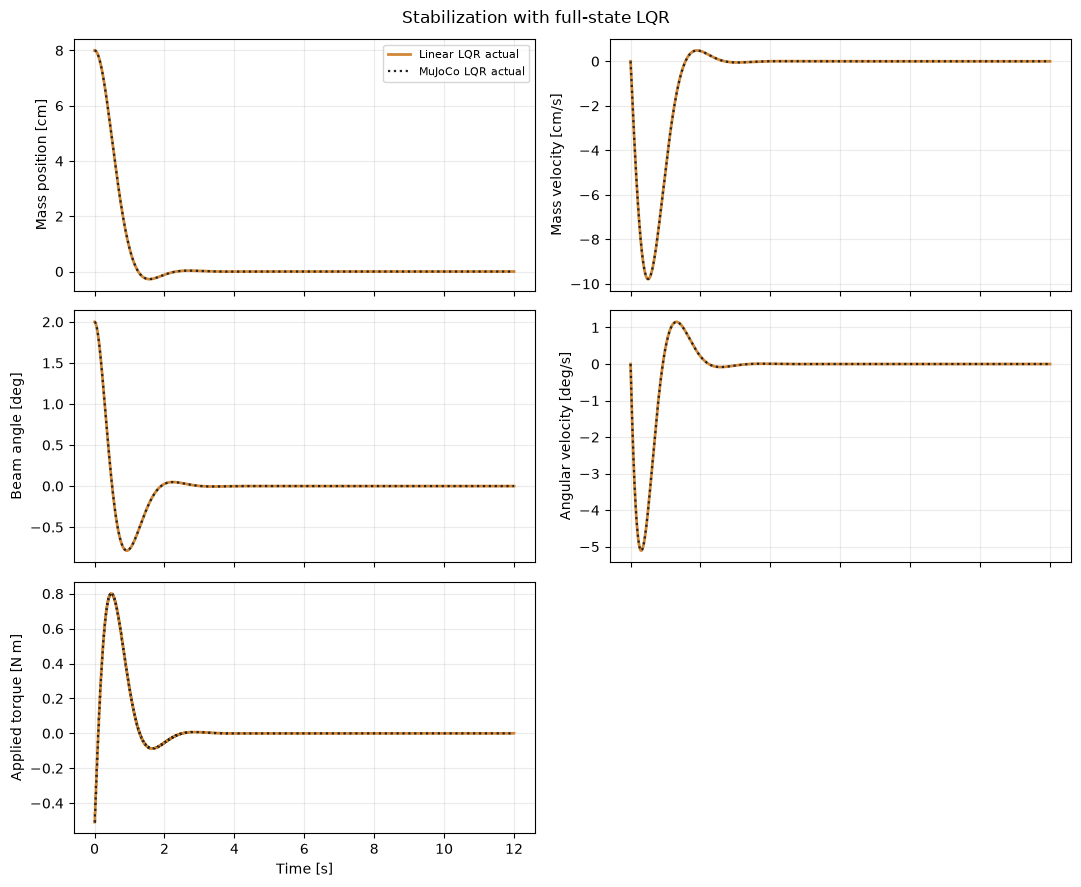

Final MuJoCo state deviation: [ 0.  0.  0. -0.]


In [4]:
T = 12.0
x0 = x_eq + np.array([0.08, 0.0, np.deg2rad(2.0), 0.0])
xhat0 = x_eq.copy()

lqr_linear = mjsim.simulate(dyn.linear(), x0, T, make_controller(dyn, F))
lqr_mujoco = mjsim.simulate(dyn, x0, T, make_controller(dyn, F))
fig = mjsim.plot_response([lqr_linear, lqr_mujoco],
                         labels=["Linear LQR", "MuJoCo LQR"], estimates=False,
                         title="Stabilization with full-state LQR")
display(fig)
plt.close(fig)
print("Final MuJoCo state deviation:", lqr_mujoco.x[-1] - x_eq)

## 2. Infinite-horizon Kalman filter
The filter estimates all four states from the measured beam angle and known applied torque. Choose an assumed continuous state-noise intensity $Q_e$ and per-sample measurement variance $R$. The wrapper converts the intensity to
$$W=\int_0^{dt}e^{A\tau}Q_e e^{A^T\tau}\,d\tau.$$
The covariance recursion combines correction and prediction. Its steady **prior covariance** $\Pi$ solves
$$\Pi=A_d\Pi A_d^T+W-A_d\Pi H^T(H\Pi H^T+R)^{-1}H\Pi A_d^T.$$
Use this solution to compute a fixed correction gain:
$$\boxed{K_\infty=\Pi H^T(H\Pi H^T+R)^{-1}.}$$
`solve_discrete_are(Ad.T, H.T, W, R)` returns $\Pi$, not the posterior covariance. The covariance after the measurement correction is $P_\infty^+=(I-K_\infty H)\Pi$.

The two nonzero entries of $Q_e$ represent uncertainty in the translational and angular acceleration equations; they have their corresponding physical units. These noise assumptions are distinct from the LQR weights.

In [5]:
Qe = np.diag([0.0, 1e-5, 0.0, 1e-5])
W = dyn.noise_covariance(Qe)
sensor_std = np.deg2rad(0.05)  # radians, per sample
R = sensor_std**2 * np.eye(p)

Pi = solve_discrete_are(Ad.T, H.T, W, R)
K_inf = np.linalg.solve(H @ Pi @ H.T + R, H @ Pi).T
J = np.eye(n) - K_inf @ H
P_post = J @ Pi @ J.T + K_inf @ R @ K_inf.T
estimator_poles = np.linalg.eigvals(Ad @ J)

print("Steady prior covariance Pi =\n", Pi)
print("Fixed correction gain K_inf =\n", K_inf)
print("Predictor error poles =", estimator_poles)
assert np.max(np.abs(estimator_poles)) < 1
assert np.allclose(Pi, Ad @ P_post @ Ad.T + W)
assert np.min(np.linalg.eigvalsh(Pi)) > 0

Steady prior covariance Pi =
 [[ 0.  0. -0. -0.]
 [ 0.  0. -0. -0.]
 [-0. -0.  0.  0.]
 [-0. -0.  0.  0.]]
Fixed correction gain K_inf =
 [[-0.3022]
 [-0.447 ]
 [ 0.1093]
 [ 0.632 ]]
Predictor error poles = [0.9585+0.0398j 0.9585-0.0398j 0.9837+0.0161j 0.9837-0.0161j]


### Implement the fixed-gain observer
The wrapper calls `controller(t, xhat)` **before** reading the current measurement. For $k\geq1$, `xhat` is the prior $\hat x_k^-$.

Here $z_k$ is the noisy sensor measurement; $z_{\rm eq}$ is the nominal output stored as `dyn.y_eq`. There is no measurement $z_0$. Initialize $\hat x_0=m_0$, apply $u_0$, and predict
$$\hat x_1^-=x_{\rm eq}+A_d(\hat x_0-x_{\rm eq})+B_d(u_0-u_{\rm eq}).$$
The notebook passes `first_measurement=1` to the wrapper. At $k=0$, the observer receives `z=None` and only predicts. From $k=1$ onward, the observer callback performs
$$\nu_k=z_k-z_{\rm eq}-H(\hat x_k^--x_{\rm eq})-D(u_k-u_{\rm eq}),$$
$$\hat x_k^+=\hat x_k^-+K_\infty\nu_k,$$
$$\hat x_{k+1}^-=x_{\rm eq}+A_d(\hat x_k^+-x_{\rm eq})+B_d(u_k-u_{\rm eq}).$$
It returns the next prior. The supplied $u_k$ is the **applied, saturated input**. No covariance iteration is needed in this callback because the gain is fixed. Using it from the first sample is a steady-state design, generally not transient-optimal for a different initial covariance.

In [6]:
def make_observer(dyn, K_inf):
    """Return the next prior using a fixed Kalman correction gain."""
    Ad, Bd = dyn.discrete()
    H, D = dyn.C, dyn.D
    z_eq = dyn.y_eq
    def observer(t, xhat_prior, u_applied, z):
        dx_prior = xhat_prior - dyn.x_eq
        du = u_applied - dyn.u_eq
        dx_post = dx_prior
        if z is not None:  # first measurement is z_1; no correction at k=0
            innovation = z - z_eq - H @ dx_prior - D @ du
            dx_post = dx_prior + K_inf @ innovation
        return dyn.x_eq + Ad @ dx_post + Bd @ du
    return observer

observer = make_observer(dyn, K_inf)

## 3. LQG stabilization simulation
Combine the LQR gain with the fixed-gain Kalman estimate:
$$u_k=u_{\rm eq}-F(\hat x_k^--x_{\rm eq}).$$
For this predictor-timing interface, the nominal regulator and estimator error blocks are $A_d-B_dF$ and $A_d(I-K_\infty H)$. Both are stable. The controller uses measurements through the previous sample; it does not use the current measurement before that measurement is acquired.

The gain designs are for the unconstrained linear model. Saturation and nonlinear motion require simulation verification. The estimator assumes a small process uncertainty, while the simulations below inject sensor noise only. This demonstrates stabilization with an LQG design; it is not an exact stochastic-optimality test of the nonlinear plant.

Both trials use the same initial condition and sensor-noise seed. The initial estimate is the equilibrium, so the controller must respond while the filter corrects its initial error. Small fluctuations remain under persistent measurement noise.

Measurements start at $k=1$. With the wrapper’s predictor-feedback order, $u_1$ uses $\hat x_1^-$; the correction from $z_1$ enters $\hat x_2^-$ and affects $u_2$. This is the same callback timing as the classroom wrapper.

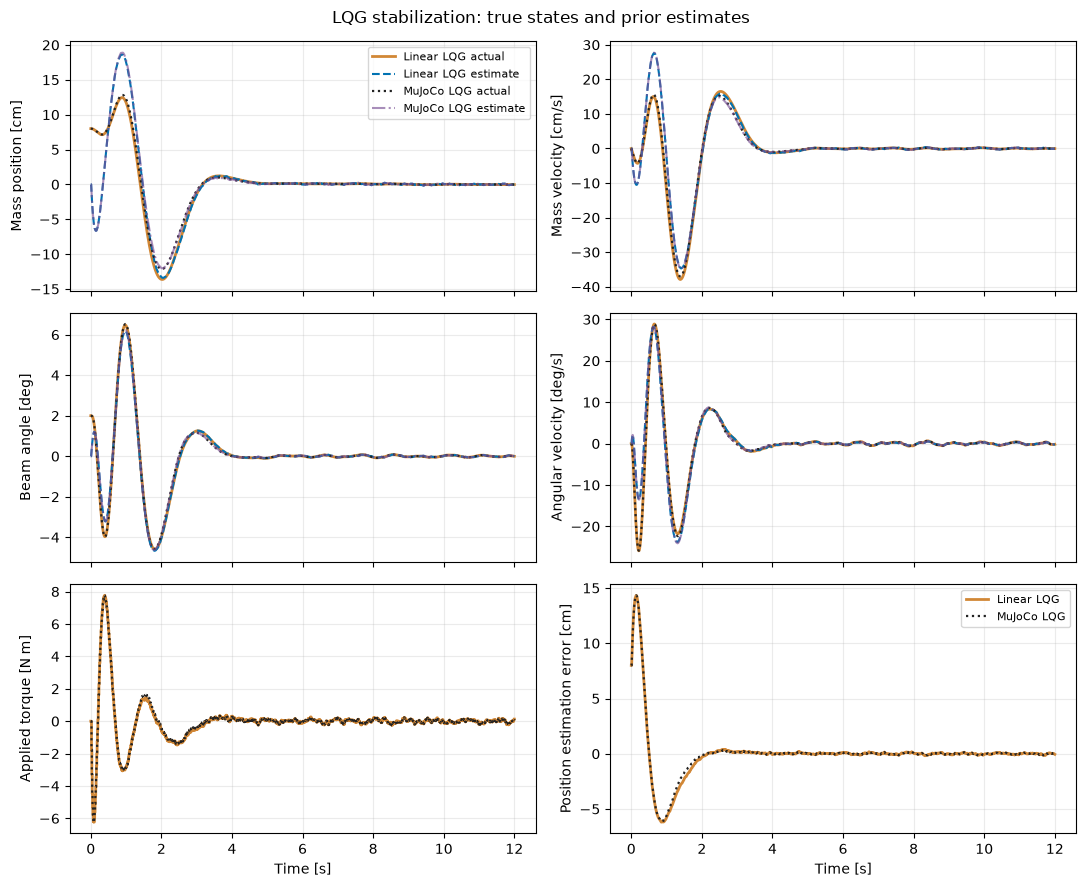

In [7]:
lqg_linear = mjsim.simulate(
    dyn.linear(), x0, T, make_controller(dyn, F),
    observer=make_observer(dyn, K_inf), xhat0=xhat0,
    noise_std=sensor_std, seed=6246, first_measurement=1)
lqg_mujoco = mjsim.simulate(
    dyn, x0, T, make_controller(dyn, F),
    observer=make_observer(dyn, K_inf), xhat0=xhat0,
    noise_std=sensor_std, seed=6246, first_measurement=1)

fig = mjsim.plot_response([lqg_linear, lqg_mujoco],
                         labels=["Linear LQG", "MuJoCo LQG"],
                         title="LQG stabilization: true states and prior estimates")
display(fig)
plt.close(fig)

# No measurement at k=0: the first stored prediction uses only xhat0 and u0.
for res in (lqg_linear, lqg_mujoco):
    assert np.isnan(res.y[0]).all()
    assert np.isfinite(res.y[1:]).all()
    expected_xhat1 = x_eq + Ad @ (xhat0 - x_eq) + Bd @ (res.u[0] - u_eq)
    assert np.allclose(res.xhat[1], expected_xhat1)

### Check the stabilization response
Use the final two seconds to summarize the residual motion. Peak torque excludes the final logged sample, which the wrapper does not apply. Simulator state is used for these checks and plots, not supplied to the LQG controller.

In [8]:
rows = []
for name, res in [("LQR / MuJoCo", lqr_mujoco),
                  ("LQG / linear", lqg_linear), ("LQG / MuJoCo", lqg_mujoco)]:
    tail = res.t >= T - 2.0
    dx = res.x - x_eq
    pos_rms = np.sqrt(np.mean(dx[tail, 0]**2))
    angle_rms = np.rad2deg(np.sqrt(np.mean(dx[tail, 2]**2)))
    peak_u = np.max(np.abs(res.u[:-1]))
    rows.append((name, pos_rms, angle_rms, peak_u))
    assert np.isfinite(res.x).all()
    assert peak_u <= np.max(dyn.u_limit) + 1e-12

header = "| Design | Tail position RMS [m] | Tail angle RMS [deg] | Peak torque [N m] |\n|---|---:|---:|---:|\n"
body = "\n".join(f"| {name} | {pos:.5f} | {angle:.4f} | {torque:.3f} |"
                 for name, pos, angle, torque in rows)
display(Markdown(header + body))

| Design | Tail position RMS [m] | Tail angle RMS [deg] | Peak torque [N m] |
|---|---:|---:|---:|
| LQR / MuJoCo | 0.00000 | 0.0000 | 0.802 |
| LQG / linear | 0.00019 | 0.0357 | 7.767 |
| LQG / MuJoCo | 0.00019 | 0.0357 | 7.757 |

### Animate the nonlinear LQG response
Replay the actual MuJoCo state history from the LQG simulation above. This does not run a second simulation. The MP4 is also embedded in the saved notebook.

In [9]:
video_path = mjsim.animate(lqg_mujoco, "week13_ball_beam_lqg_stabilization.mp4", fps=30)
Video(video_path, embed=True)

## 4. Extension: sinusoidal reference tracking
Let $r(t)$ specify the desired ball position. First construct a feasible reference state and input:
$$\dot x_r=Ax_r+Bu_r,\qquad Cx_r=r(t).$$
Here the classroom equilibrium is zero. For a nonzero equilibrium, these equations are written in deviation coordinates.

Define a **new state and input**
$$\boxed{\tilde x=x-x_r(t),\qquad \tilde u=u-u_r(t).}$$
Subtracting the reference dynamics gives
$$\dot{\tilde x}=A\tilde x+B\tilde u.$$
The equilibrium $\tilde x=0$ now means $x=x_r(t)$: **stabilizing the new state is trajectory tracking**. With the same gain $F$ as before,
$$\tilde u=-F\widehat{\tilde x},\qquad
\widehat{\tilde x}=\hat x-x_r,\qquad
\boxed{u=u_r-F(\hat x-x_r).}$$

Continue to use $H$ and $z$ for the sensor model. The tracking matrix $C$ selects ball position; it is loaded separately from `mjsim.py`. The controller still receives only the Kalman estimate, not true ball position.

In [10]:
# Plant matrices and physical parameters continue to come from mjsim.py.
C = dyn.tracking_C
mass = dyn.params["mass"]
inertia = dyn.params["inertia"]
g = dyn.params["g"]
print("Sensor matrix H =", H)
print("Tracking matrix C =", C)

Sensor matrix H = [[0. 0. 1. 0.]]
Tracking matrix C = [[1. 0. 0. 0.]]


### Construct a feasible ball-and-beam reference
For the linearized equations supplied by the wrapper,
$$\ddot d=-g\theta,\qquad I\ddot\theta=-mgd+u,$$
set the reference ball position to $d_r=r(t)$. The equations determine the remaining reference components:
$$\boxed{x_r=\begin{bmatrix}r&\dot r&-\ddot r/g&-r^{(3)}/g\end{bmatrix}^T,
\qquad u_r=mgr-\frac{I}{g}r^{(4)}.}$$
A moving ball requires beam tilt. Subtracting only the desired position and setting all other reference states to zero would generally not describe a feasible trajectory.

Use a sinusoidal position reference
$$\boxed{r(t)=a\sin(\omega t),\qquad a=0.30\ \mathrm{m},\quad
\omega=\frac{2\pi}{T_r},\quad T_r=8\ \mathrm{s}.}$$
Its derivatives are
$$\dot r=a\omega\cos(\omega t),\qquad \ddot r=-a\omega^2\sin(\omega t),$$
$$r^{(3)}=-a\omega^3\cos(\omega t),\qquad r^{(4)}=a\omega^4\sin(\omega t).$$
Consequently, the reference tilt is $\theta_r=(a\omega^2/g)\sin(\omega t)$ and the reference torque is
$$u_r=a\left(mg-\frac{I\omega^4}{g}\right)\sin(\omega t).$$
Simulate three periods (24 s). Amplitude and period are reference-design choices; the plant parameters remain in the wrapper. The sinusoid starts at $t=0$ with nonzero reference velocity. The initial plant state need not match that motion, so the plots include an initial tracking transient.

In [11]:
reference_amplitude = 0.30  # m
reference_period = 8.0      # s
omega = 2.0 * np.pi / reference_period
tracking_duration = 3.0 * reference_period


def position_reference(t):
    """Return the sinusoidal position and its first four time derivatives."""
    a = reference_amplitude
    phase = omega * t
    return np.array([
        a * np.sin(phase),
        a * omega * np.cos(phase),
        -a * omega**2 * np.sin(phase),
        -a * omega**3 * np.cos(phase),
        a * omega**4 * np.sin(phase),
    ])


def moving_reference(t):
    """Return the feasible reference state and torque, in physical coordinates."""
    r, dr, ddr, d3r, d4r = position_reference(t)
    xr = x_eq + np.array([r, dr, -ddr / g, -d3r / g])
    ur = u_eq + np.array([mass * g * r - inertia * d4r / g])
    return xr, ur

# Verify feasibility using the plant matrices loaded from the wrapper.
for t_test in np.linspace(0.0, tracking_duration, 121):
    r, dr, ddr, d3r, d4r = position_reference(t_test)
    xr, ur = moving_reference(t_test)
    xr_dot = np.array([dr, ddr, -d3r / g, -d4r / g])
    assert np.allclose(A @ (xr - x_eq) + B @ (ur - u_eq), xr_dot)
    assert np.allclose(C @ (xr - x_eq), r)
print("Sinusoidal reference dynamics verified.")

Sinusoidal reference dynamics verified.


### Extend `make_controller` to use the new state
The controller factory now accepts `reference(t)`, returning $(x_r,u_r)$. With no reference function it returns the original stabilization controller. The feedback term is explicitly based on $\widehat{\tilde x}=\hat x-x_r$.

The continuous reference is sampled at the controller times. The same discrete LQR gain $F$ is reused, but holding the sampled reference torque is only approximately feasible for the discrete plant. Nonlinear dynamics, estimation error, and input saturation can also produce residual tracking error.

The Kalman observer is unchanged: it estimates the **actual state** using $H$, $z$, and the applied torque. Reference subtraction belongs in the controller.

In [12]:
def make_controller(dyn, F, reference=None):
    """Return controller(t, xhat) for stabilization or trajectory tracking."""
    def controller(t, xhat):
        if reference is None:
            xr, ur = dyn.x_eq, dyn.u_eq
        else:
            xr, ur = reference(t)
        x_tilde_hat = xhat - xr
        return ur - F @ x_tilde_hat
    return controller

# Setting the reference to the equilibrium recovers the stabilization command.
probe = x_eq + np.array([0.02, 0.0, 0.01, 0.0])
assert np.allclose(make_controller(dyn, F)(0.0, probe),
                   u_eq - F @ (probe - x_eq))

### Simulate and plot the new state
Use the same LQG design for the sampled linear plant and MuJoCo. The first measurement is still $z_1$ (`first_measurement=1`), and the controller uses the current prior estimate.

The top four panels below plot the **new state** $x-x_r$. Its zero line represents perfect reference tracking. The bottom panels show ball position against its command and applied torque against the reference torque. All plotted true-state quantities are evaluation data only.

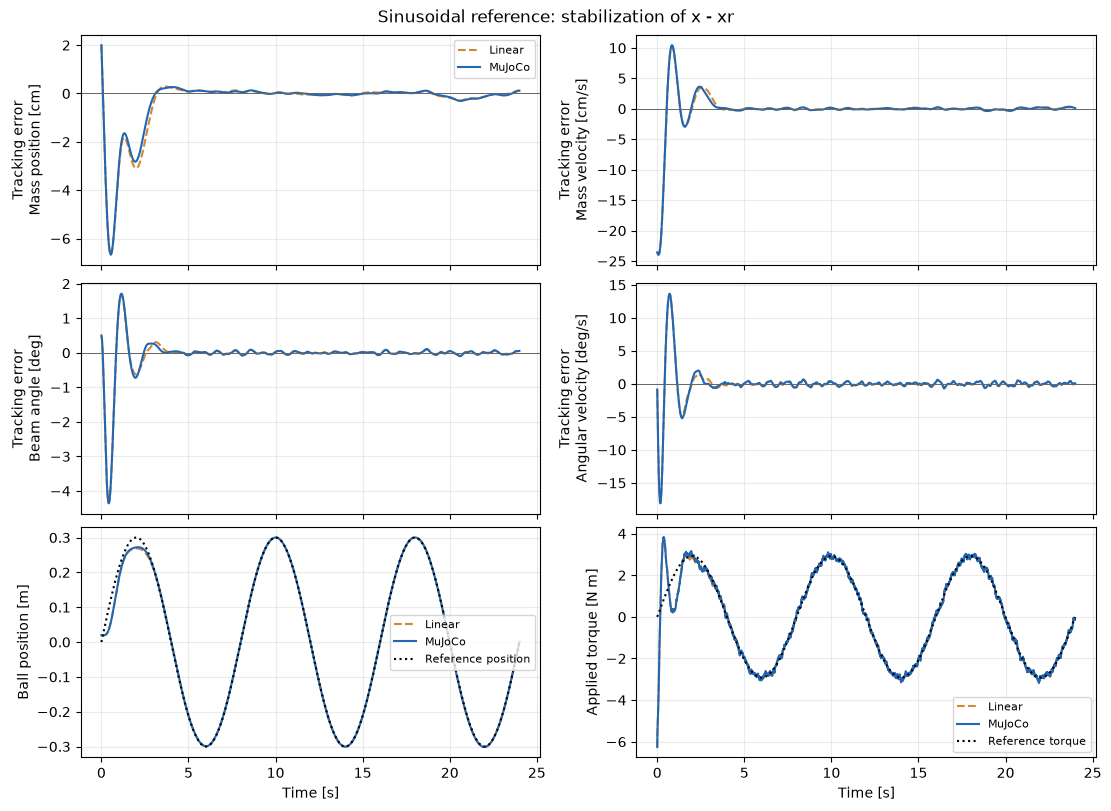

In [13]:
def simulate_tracking(reference, duration):
    results = {}
    # A small initial error makes the stabilization of x - xr visible.
    tracking_x0 = x_eq + np.array([0.02, 0.0, np.deg2rad(0.5), 0.0])
    for label, plant in [("Linear", dyn.linear()), ("MuJoCo", dyn)]:
        results[label] = mjsim.simulate(
            plant, tracking_x0, duration, make_controller(plant, F, reference),
            observer=make_observer(plant, K_inf), xhat0=x_eq.copy(),
            noise_std=sensor_std, seed=6246, first_measurement=1)
    return results


def plot_tracking(results, reference, title):
    fig, axes = plt.subplots(3, 2, figsize=(11, 8), sharex=True,
                             layout="constrained")
    display_scale = np.asarray(dyn.spec["display"]["scale"])
    state_labels = dyn.spec["display"]["labels"]
    for label, res in results.items():
        reference_values = [reference(tk) for tk in res.t]
        xr = np.array([value[0] for value in reference_values])
        ur = np.array([value[1] for value in reference_values])
        x_tilde = res.x - xr
        style = dict(color="#d18736", ls="--") if label == "Linear" else dict(color="#2366b1", ls="-")
        for j in range(n):
            axes.flat[j].plot(res.t, x_tilde[:, j] * display_scale[j],
                              label=label, **style)
        axes[2, 0].plot(res.t, (res.x @ C.T).ravel(), label=label, **style)
        axes[2, 1].plot(res.t[:-1], res.u[:-1, 0], label=label, **style)
    for j in range(n):
        axes.flat[j].axhline(0.0, color="0.4", lw=0.7)
        axes.flat[j].set_ylabel("Tracking error\n" + state_labels[j])
    axes[2, 0].plot(res.t, (xr @ C.T).ravel(), "k:", label="Reference position")
    axes[2, 1].plot(res.t[:-1], ur[:-1, 0], "k:", label="Reference torque")
    axes[2, 0].set_ylabel("Ball position [m]")
    axes[2, 1].set_ylabel("Applied torque [N m]")
    for ax in axes.flat:
        ax.grid(alpha=0.25)
    for ax in axes[-1]:
        ax.set_xlabel("Time [s]")
        ax.legend(fontsize=8)
    axes[0, 0].legend(fontsize=8)
    fig.suptitle(title)
    return fig


moving_results = simulate_tracking(moving_reference, duration=tracking_duration)
fig = plot_tracking(moving_results, moving_reference,
                    "Sinusoidal reference: stabilization of x - xr")
display(fig)
plt.close(fig)

### Animate sinusoidal tracking
Replay the nonlinear LQG trajectory above. The requested ball position oscillates between −0.3 m and +0.3 m with an 8 s period. Use the plots to compare the realized position with the reference.

In [14]:
moving_video_path = mjsim.animate(
    moving_results["MuJoCo"], "week13_ball_beam_sinusoidal_tracking.mp4", fps=30)
Video(moving_video_path, embed=True)

## 5. Extension: fixed-reference tracking
Now let $r(t)=r_0$ be constant. All reference derivatives vanish, so
$$\boxed{x_r=\begin{bmatrix}r_0&0&0&0\end{bmatrix}^T,\qquad u_r=mgr_0.}$$
The same new state $\tilde x=x-x_r$ measures displacement from this equilibrium. Use exactly the same controller,
$$u=u_r-F(\hat x-x_r).$$
The nonzero $u_r$ balances the ball's gravitational torque at the displaced position. Simply applying $-F\hat x$ would continue regulating the original equilibrium.

We can obtain the constant reference from the **loaded matrices** by solving
$$\begin{bmatrix}A_d-I&B_d\\C&0\end{bmatrix}
\begin{bmatrix}N_x\\N_u\end{bmatrix}
=\begin{bmatrix}0\\1\end{bmatrix},\qquad x_r=N_xr_0,\quad u_r=N_ur_0.$$
For this model, the result agrees with the formula above. If desired, expand the controller as $u=-F\hat x+Nr_0$, with $N=N_u+FN_x$. The implementation below retains $\hat x-x_r$ to make the new-state interpretation visible.

Reference state xr = [0.1 0.  0.  0. ]
Reference torque ur = [0.981] N m
Equivalent precompensator N = [-31.2162]


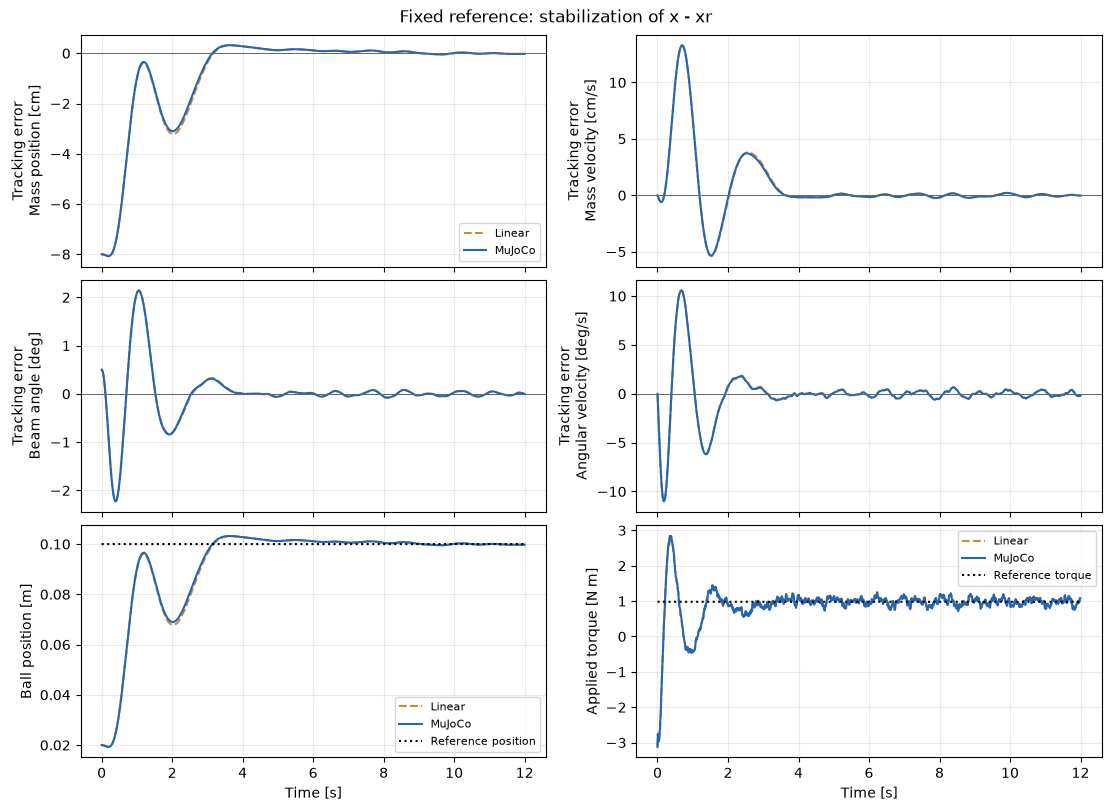

In [15]:
fixed_position = 0.10  # m, held for the entire experiment
regulator = np.block([[Ad - np.eye(n), Bd],
                      [C, np.zeros((C.shape[0], m))]])
rhs = np.concatenate([np.zeros(n), np.ones(C.shape[0])])
solution = np.linalg.solve(regulator, rhs)
Nx, Nu = solution[:n], solution[n:]
N = Nu + F @ Nx


def fixed_reference(t):
    xr = x_eq + Nx * fixed_position
    ur = u_eq + Nu * fixed_position
    return xr, ur


xr_fixed, ur_fixed = fixed_reference(0.0)
assert np.allclose(A @ (xr_fixed - x_eq) + B @ (ur_fixed - u_eq), 0.0)
assert np.allclose(C @ (xr_fixed - x_eq), fixed_position)
assert np.allclose(Nu, mass * g)
print("Reference state xr =", xr_fixed)
print("Reference torque ur =", ur_fixed, "N m")
print("Equivalent precompensator N =", N)

fixed_results = simulate_tracking(fixed_reference, duration=12.0)
fig = plot_tracking(fixed_results, fixed_reference,
                    "Fixed reference: stabilization of x - xr")
display(fig)
plt.close(fig)

### Animate fixed-reference tracking
The controller brings the ball to 0.1 m, returns the beam angle toward zero, and maintains the holding torque. This video replays the fixed-reference MuJoCo result.

In [16]:
fixed_video_path = mjsim.animate(
    fixed_results["MuJoCo"], "week13_ball_beam_fixed_tracking.mp4", fps=30)
Video(fixed_video_path, embed=True)

### Evaluate tracking
Report position RMSE, the residual error over the final two seconds, and the largest applied torque. The final logged command is excluded because it is not applied. The reference commands here stay within the physical beam length and torque limit; larger or faster commands must be checked again.

In [17]:
tracking_rows = []
for experiment, results, reference in [
        ("Sinusoidal", moving_results, moving_reference),
        ("Fixed", fixed_results, fixed_reference)]:
    for label, res in results.items():
        xr = np.array([reference(tk)[0] for tk in res.t])
        x_tilde = res.x - xr
        output_error = (x_tilde @ C.T).ravel()
        tail = res.t >= res.t[-1] - 2.0
        rmse = np.sqrt(np.mean(output_error**2))
        tail_rmse = np.sqrt(np.mean(output_error[tail]**2))
        peak_u = np.max(np.abs(res.u[:-1]))
        tracking_rows.append((experiment, label, rmse, tail_rmse, peak_u))
        assert np.isfinite(res.x).all()
        assert peak_u <= np.max(dyn.u_limit) + 1e-12
        assert np.isnan(res.y[0]).all() and np.isfinite(res.y[1:]).all()

header = "| Reference | Plant | Position RMSE [m] | Tail RMS [m] | Peak torque [N m] |\n|---|---|---:|---:|---:|\n"
body = "\n".join(f"| {kind} | {plant} | {rmse:.5f} | {tail:.5f} | {peak:.3f} |"
                 for kind, plant, rmse, tail, peak in tracking_rows)
display(Markdown(header + body))

| Reference | Plant | Position RMSE [m] | Tail RMS [m] | Peak torque [N m] |
|---|---|---:|---:|---:|
| Sinusoidal | Linear | 0.01195 | 0.00069 | 6.254 |
| Sinusoidal | MuJoCo | 0.01149 | 0.00068 | 6.254 |
| Fixed | Linear | 0.01998 | 0.00019 | 3.122 |
| Fixed | MuJoCo | 0.01980 | 0.00019 | 3.122 |

### Discussion
- Why does $\tilde x=0$ correspond to a moving physical state in Section 4 but a fixed state in Section 5?
- What happens if you omit $u_r$, or subtract the reference position without the other components of $x_r$?
- Increase the sinusoid period and explain its effect on reference tilt and torque. Then increase the amplitude. Reduce the torque limit and inspect whether the new state still remains close to zero.
- For a fixed reference, why is the holding torque nonzero? How would an unknown constant torque disturbance affect the final position?

The same feedback gain stabilizes the new state in both cases. Exact tracking conclusions require a feasible reference, adequate state estimation, and operation consistent with the model and actuator limits.